# C-01 · County and judge differences
**Yixuan Wen · Role C · 2026-11-08**

This notebook describes bail-set/remand decisions in the NYC main sample. `y_detain = 1` means bail was set or the defendant was remanded; it does **not** measure actual detention. All outcome EDA uses training years only. Validation/test years contribute only pre-specified, outcome-free judge coverage and caseload summaries.

**Questions:** How much do county/judge rates differ? How do differences change within severity and after a coarse charge-mix adjustment? What training caseload threshold is reasonable? How much future caseload lacks a training-period judge identity?

This is descriptive analysis. Nonrandom judge assignment, omitted case information and small samples preclude causal or discrimination claims. No prediction model is fitted here.


In [1]:
%load_ext autoreload
%autoreload 2
%matplotlib inline
import sys; sys.path.append("..")
from src import config
from src.fairness import (
    load_court_judge_inputs, category_counts, county_rates, judge_rates,
    judge_percentiles, coverage_tables, identity_caseload_summaries,
    plot_county_rates, plot_judge_spread,
)
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display, Markdown
from importlib.metadata import version

pd.set_option("display.max_rows", 80)
print("Python:", sys.version.split()[0])
print({p: version(p) for p in ["pandas", "numpy", "pyarrow", "matplotlib"]})
print("Training years:", config.TRAIN_YEARS)
print("Judge threshold:", config.MIN_JUDGE_CASES, "| Reporting minimum:", config.MIN_GROUP_N)


Python: 3.11.18
{'pandas': '3.1.1', 'numpy': '2.4.6', 'pyarrow': '26.0.1', 'matplotlib': '3.11.2'}
Training years: [2021, 2022]
Judge threshold: 100 | Reporting minimum: 100


## 1. Sample and temporal safeguards
Run `python -m src.build_dataset` from the repository root in the `pol408` environment first. The data loader projects training outcomes separately from all-year identity metadata. Future outcome columns are not loaded into the coverage frame. Main-sample membership follows the existing A pipeline, including its pre-specified exclusions.

Sample sizes are checked against the committed `reports/sample_flow.csv`; no outcome rate is calculated for validation/test years. Small reporting cells are removed before display or export.


In [2]:
training, metadata = load_court_judge_inputs()
assert config.TARGET_Q1 not in metadata.columns
assert training[config.YEAR_COL].isin(config.TRAIN_YEARS).all()
flow = pd.read_csv(config.SAMPLE_FLOW_FILE)
main_row = flow.loc[flow["step"].eq("MAIN")].iloc[0]
sample_check = metadata.groupby(config.YEAR_COL).size().rename("n").reset_index()
sample_check["expected_n"] = sample_check[config.YEAR_COL].map(lambda y: int(main_row[str(y)]))
assert sample_check["n"].eq(sample_check["expected_n"]).all()
display(sample_check)
print(f"Training main sample: {len(training):,} cases; bail-set/remand rate {training[config.TARGET_Q1].mean():.2%}.")


,arraign_year,n,expected_n
0,2021,89189,89189
1,2022,104007,104007
2,2023,120457,120457
3,2024,135821,135821


Training main sample: 193,196 cases; bail-set/remand rate 12.93%.


### Observed categories
These counts verify the actual values used below. Cells below `MIN_GROUP_N` are omitted; absence from this table does not mean a category is absent from the data. No individual case or judge name is displayed.


In [3]:
display(category_counts(training))


,field,value,n
0,county_name,Kings,59241
1,county_name,Queens,45578
2,county_name,New York,45088
3,county_name,Bronx,33160
4,county_name,Richmond,10129
5,top_severity_at_arraign,Misdemeanor,134180
6,top_severity_at_arraign,Felony,59016
7,top_charge_weight_at_arraign,AM,119732
8,top_charge_weight_at_arraign,DF,20432
9,top_charge_weight_at_arraign,CF,14555


## 2. County rates: pooled and within severity
Rates are case-weighted within each county/severity cell. Comparing pooled and within-severity rates helps assess whether the county contrast reflects differing shares of felony and misdemeanor cases. This does not fully control for case mix.


,county_name,n,observed_rate,severity
0,Bronx,"33,160",14.02%,All
1,Kings,"59,241",12.48%,All
2,New York,"45,088",14.88%,All
3,Queens,"45,578",10.63%,All
4,Richmond,"10,129",13.64%,All
5,Bronx,"10,290",39.10%,Felony
6,Bronx,"22,870",2.74%,Misdemeanor
7,Kings,"18,561",35.48%,Felony
8,Kings,"40,680",1.98%,Misdemeanor
9,New York,"14,188",40.76%,Felony


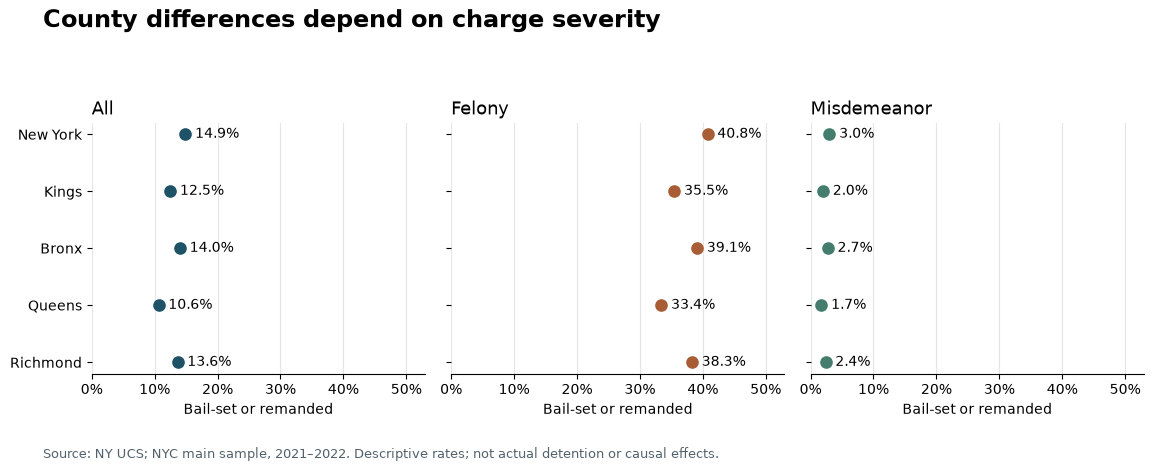

In [4]:
county = county_rates(training)
display(county.style.format({"n": "{:,.0f}", "observed_rate": "{:.2%}"}))
fig_county = plot_county_rates(county)
plt.show()


## 3. Actual judge caseloads and the encoding threshold
`other` is a pooled category and `unseen` is a pooled category: neither is one judge. Counting unique published IDs would underestimate the number of judges.

To recover **aggregate** identity counts, the helper reads only raw case-ID and judge-name columns, matches them to main-sample IDs, and discards names internally. It never reads future outcomes and never returns names, a mapping, or individual low-count judges. These counts describe recorded identities, not independently verified unique people.

The threshold comparison is training-only: the current configured minimum versus twice that minimum (currently 100 versus 200). Future-year coverage is not used to tune this threshold.


In [5]:
thresholds, caseload_distribution = identity_caseload_summaries(metadata)
display(thresholds.style.format({"n": "{:,.0f}", "n_total": "{:,.0f}", "case_share": "{:.2%}"}))
display(caseload_distribution.loc[caseload_distribution["period"].eq("Training")].style.format(precision=1))
base, stricter = thresholds.iloc[0], thresholds.iloc[1]
display(Markdown(
    f"**Threshold recommendation:** retain the existing `{config.MIN_JUDGE_CASES}`-case encoding minimum for now; "
    f"it retains **{int(base.n_judges)} judges / {base.case_share:.2%} of training cases**. "
    f"A minimum of {int(stricter.min_cases)} retains {int(stricter.n_judges)} judges / {stricter.case_share:.2%}, "
    f"a loss of {(base.case_share - stricter.case_share)*100:.2f} percentage points of coverage. "
    "Use the stricter threshold as a training-only sensitivity description, not as a test-driven change. "
    f"A threshold of {config.MIN_JUDGE_CASES} does not guarantee precise rates, especially for rare outcomes; "
    f"every severity-specific rate separately requires at least {config.MIN_GROUP_N} cases. "
    "This notebook does not modify `config.py` or the published encoding."
))


,min_cases,n_judges,n,n_total,case_share,n_judges_below_threshold
0,100,184,"191,877","193,196",99.32%,59
1,200,146,"186,250","193,196",96.40%,97


,period,cohort,n_judges,n,caseload_p10,caseload_p50,caseload_p90,n_judges_ge_min
0,Training,All named identities,243,193196,5.2,265.0,2273.8,184


**Threshold recommendation:** retain the existing `100`-case encoding minimum for now; it retains **184 judges / 99.32% of training cases**. A minimum of 200 retains 146 judges / 96.40%, a loss of 2.91 percentage points of coverage. Use the stricter threshold as a training-only sensitivity description, not as a test-driven change. A threshold of 100 does not guarantee precise rates, especially for rare outcomes; every severity-specific rate separately requires at least 100 cases. This notebook does not modify `config.py` or the published encoding.

## 4. Judge variation and coarse case-mix adjustment
Only individually encoded judges (`J...`) with sufficient training caseload enter the judge-rate comparison. P10/P50/P90 are **unweighted percentiles across judges**, not percentiles across cases. Within-severity summaries additionally require `MIN_GROUP_N` cases for that judge in that severity; the eligible judge sets can therefore differ.

For training case $i$ in charge-weight × violent-indicator cell $s$, assign the pooled training rate $r_s$. For judge $j$:

$$E_j = \frac{1}{n_j}\sum_{i\in j}r_{s(i)},\qquad D_j = O_j-E_j.$$

Here $O_j$ is the actual bail-set/remand rate. The reference includes all training cases, including the judge's own cases and pooled low-volume judges. It is in-sample indirect standardization, not a fitted risk model or leave-one-judge-out estimate. Small reference cells can contribute internally but are never published. Adjustment omits prior records, pending charges, county, evidence and other circumstances; remaining differences cannot be attributed to judges.

Both raw rates and adjusted differences are summarized overall and within each observed severity.


,severity,n_judges,n,observed_rate_p10,observed_rate_p50,observed_rate_p90,observed_minus_expected_p10,observed_minus_expected_p50,observed_minus_expected_p90
0,All,184,191877,8.18%,13.32%,21.04%,-4.37%,-0.17%,4.90%
1,Felony,108,53705,29.10%,37.75%,47.04%,-8.19%,-0.10%,9.29%
2,Misdemeanor,165,131794,0.55%,2.20%,4.96%,-1.73%,-0.12%,2.57%


Individual anonymous judge cells are exported to reports/c01_judge_rates.csv; every cell passes the reporting minimum.


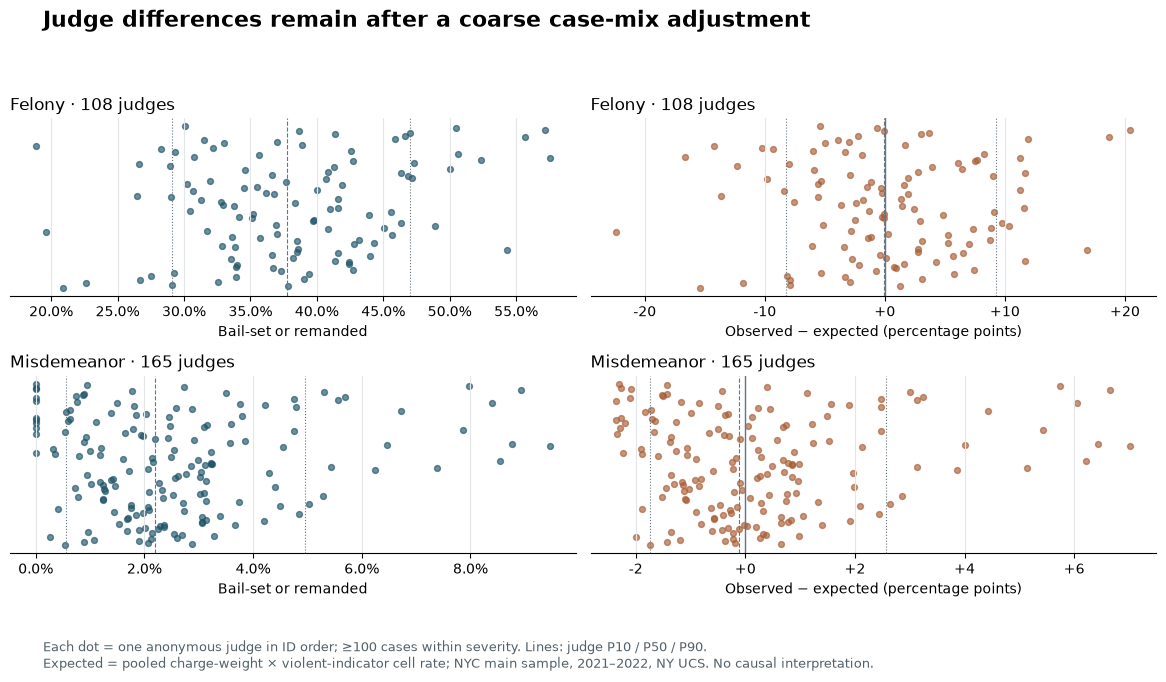

In [6]:
rates = judge_rates(training)
percentiles = judge_percentiles(rates)
display(percentiles.style.format({c: "{:.2%}" for c in percentiles.columns if "_p" in c}))
print("Individual anonymous judge cells are exported to reports/c01_judge_rates.csv; every cell passes the reporting minimum.")
fig_judge = plot_judge_spread(rates)
plt.show()


## 5. Future judge coverage — no outcomes
"Unseen" means absent from the **training main sample**, not necessarily a newly appointed judge. A judge appearing in both future years remains unseen relative to training.

Yearly and monthly tables use all main-sample cases as denominators, including missing identities; cell suppression occurs **after** denominators are calculated. A missing/suppressed status is not zero. `judge_id_final` is shown only as a pre-specified test-year encoding diagnostic (fit years = training + validation), never to select a model or change the threshold.

**Scope resolution:** the role handoff also requests future new-versus-old outcome rates. That conflicts with its training-only EDA rule and the test freeze. No validation/test outcome comparison is performed here. Individual new-judge tables cannot be produced with published `unseen` IDs without an A-owned interface extension; this notebook provides aggregate identity counts and caseload distributions instead.


In [7]:
coverage_yearly, coverage_monthly = coverage_tables(metadata)
display(coverage_yearly.style.format({"n": "{:,.0f}", "n_total": "{:,.0f}", "case_share": "{:.2%}"}))
future_caseloads = caseload_distribution.loc[~caseload_distribution["period"].eq("Training")]
display(future_caseloads.style.format(precision=1))
monthly_unseen = coverage_monthly.loc[
    coverage_monthly["coding"].eq("judge_id")
    & coverage_monthly[config.YEAR_COL].isin([config.VALID_YEAR, config.TEST_YEAR])
    & coverage_monthly["status"].eq("unseen")
]
display(monthly_unseen.style.format({"case_share": "{:.2%}"}))


,arraign_year,status,n,n_total,case_share,coding
0,2021,coded,"88,393","89,189",99.11%,judge_id
1,2021,other,796,"89,189",0.89%,judge_id
2,2022,coded,"103,484","104,007",99.50%,judge_id
3,2022,other,523,"104,007",0.50%,judge_id
4,2023,coded,"76,680","120,457",63.66%,judge_id
5,2023,other,"7,013","120,457",5.82%,judge_id
6,2023,unseen,"36,764","120,457",30.52%,judge_id
7,2024,coded,"58,336","135,821",42.95%,judge_id
8,2024,other,"5,641","135,821",4.15%,judge_id
9,2024,unseen,"71,844","135,821",52.90%,judge_id


,period,cohort,n_judges,n,caseload_p10,caseload_p50,caseload_p90,n_judges_ge_min
1,2023,Unseen in training main sample,27,36764,1.0,1166.0,3360.0,19
2,2023,Seen in training main sample,169,83693,8.0,178.0,1426.6,119
3,2024,Unseen in training main sample,62,71844,1.0,437.5,3415.6,36
4,2024,Seen in training main sample,152,63977,15.0,158.0,1342.9,102


,arraign_year,arraign_month,status,n,n_total,case_share,coding
29,2023,2,unseen,1175,8958,13.12%,judge_id
32,2023,3,unseen,2753,9978,27.59%,judge_id
35,2023,4,unseen,2679,10028,26.72%,judge_id
38,2023,5,unseen,3393,10545,32.18%,judge_id
41,2023,6,unseen,4356,10423,41.79%,judge_id
44,2023,7,unseen,3752,10318,36.36%,judge_id
47,2023,8,unseen,4308,10511,40.99%,judge_id
50,2023,9,unseen,3813,9861,38.67%,judge_id
53,2023,10,unseen,3348,10480,31.95%,judge_id
56,2023,11,unseen,3467,10072,34.42%,judge_id


## 6. Findings and handoff
The following text is calculated from the tables above. Differences are descriptive; statistical uncertainty and full model residuals belong to later work. No significance tests are used to select judges. The two figures omit names and use the same reporting rule as the tables.


In [8]:
bullets = []
for severity, group in county.groupby("severity", sort=False):
    low = group.loc[group["observed_rate"].idxmin()]
    high = group.loc[group["observed_rate"].idxmax()]
    bullets.append(f"**County / {severity}:** {low.county_name} {low.observed_rate:.2%} to {high.county_name} {high.observed_rate:.2%}; range {(high.observed_rate-low.observed_rate)*100:.2f} percentage points.")
for _, row in percentiles.iterrows():
    bullets.append(f"**Judges / {row['severity']}:** {int(row.n_judges)} eligible judges; raw P10/P50/P90 = {row.observed_rate_p10:.2%} / {row.observed_rate_p50:.2%} / {row.observed_rate_p90:.2%}; adjusted P10/P50/P90 = {row.observed_minus_expected_p10*100:+.2f} / {row.observed_minus_expected_p50*100:+.2f} / {row.observed_minus_expected_p90*100:+.2f} percentage points.")
for _, row in coverage_yearly.loc[coverage_yearly["status"].eq("unseen")].iterrows():
    bullets.append(f"**Coverage / {int(row[config.YEAR_COL])}, {row.coding}:** {row.case_share:.2%} of cases are unseen; this is not an outcome statistic.")
display(Markdown("\n\n".join("- " + b for b in bullets)))
display(Markdown("**Action for the team:** compare CASE → +COURT → +JUDGE on validation data, and pre-specify a separate comparison among already encoded judges. Coordinate the EDA slide with Yanqi; send the threshold recommendation and the deferred future-outcome/individual-ID request to Yiling. No messages have been sent automatically."))


- **County / All:** Queens 10.63% to New York 14.88%; range 4.26 percentage points.

- **County / Felony:** Queens 33.41% to New York 40.76%; range 7.35 percentage points.

- **County / Misdemeanor:** Queens 1.73% to New York 3.00%; range 1.28 percentage points.

- **Judges / All:** 184 eligible judges; raw P10/P50/P90 = 8.18% / 13.32% / 21.04%; adjusted P10/P50/P90 = -4.37 / -0.17 / +4.90 percentage points.

- **Judges / Felony:** 108 eligible judges; raw P10/P50/P90 = 29.10% / 37.75% / 47.04%; adjusted P10/P50/P90 = -8.19 / -0.10 / +9.29 percentage points.

- **Judges / Misdemeanor:** 165 eligible judges; raw P10/P50/P90 = 0.55% / 2.20% / 4.96%; adjusted P10/P50/P90 = -1.73 / -0.12 / +2.57 percentage points.

- **Coverage / 2023, judge_id:** 30.52% of cases are unseen; this is not an outcome statistic.

- **Coverage / 2024, judge_id:** 52.90% of cases are unseen; this is not an outcome statistic.

- **Coverage / 2024, judge_id_final:** 28.18% of cases are unseen; this is not an outcome statistic.

**Action for the team:** compare CASE → +COURT → +JUDGE on validation data, and pre-specify a separate comparison among already encoded judges. Coordinate the EDA slide with Yanqi; send the threshold recommendation and the deferred future-outcome/individual-ID request to Yiling. No messages have been sent automatically.

## 7. Export and reproducibility checks
Exports contain aggregate tables and anonymous judge cells only. The outcome-free coverage exports are kept separate. Processed case-level data remain ignored by git. Figure labels use bail-set/remand terminology.

Before submitting: restart and run all, run `python -m pytest tests/test_fairness.py`, review the C-01 status/CHANGELOG/AI-use entry, and have Yiling review the PR. Commit/push are performed by the operator under `AGENTS.md`.


In [9]:
assert rates["n"].ge(config.MIN_GROUP_N).all()
assert rates["judge_id"].str.fullmatch(r"J\d+").all()
assert rates["expected_rate"].between(0, 1).all()
assert training[config.YEAR_COL].isin(config.TRAIN_YEARS).all()
assert config.TARGET_Q1 not in metadata.columns
assert all("judge_name" not in table.columns for table in
           [county, rates, percentiles, thresholds, caseload_distribution, coverage_yearly, coverage_monthly])
config.REPORTS.mkdir(parents=True, exist_ok=True)
config.FIGURES.mkdir(parents=True, exist_ok=True)
tables = {
    "county_rates": county, "judge_rates": rates, "judge_percentiles": percentiles,
    "judge_thresholds": thresholds, "judge_caseload_distribution": caseload_distribution,
    "judge_coverage_yearly": coverage_yearly, "judge_coverage_monthly": coverage_monthly,
}
for name, table in tables.items():
    assert table["n"].ge(config.MIN_GROUP_N).all()
    table.to_csv(config.REPORTS / f"c01_{name}.csv", index=False)
fig_county.savefig(config.FIGURES / "c01_county_rates.png", dpi=200, facecolor="white")
fig_judge.savefig(config.FIGURES / "c01_judge_spread.png", dpi=200, facecolor="white")
print("PASS: sample counts, training-only outcomes, coverage projection, anonymous IDs, and minimum cell sizes.")
print("Saved", len(tables), "aggregate tables and 2 deck figures.")


PASS: sample counts, training-only outcomes, coverage projection, anonymous IDs, and minimum cell sizes.
Saved 7 aggregate tables and 2 deck figures.
